# Étape 2 — Modèle RNN : prédire la valeur suivante d'une séquence

Architecture (tableau, partie 2) :

```
h0 = 0 → [RNN 16 unités] → h1 → [RNN 16 unités] → h2 → ... → [RNN 16 unités] → hn → Linear(16 → 1) → ŷ
             ↑ x1                    ↑ x2                          ↑ xn
```

Les cellules dessinées sont **la même couche réutilisée à chaque instant** (mêmes poids) :

$$h_t = \tanh(W_{ih}x_t + W_{hh}h_{t-1} + b)$$

Dimensions : `(B, 10, 1) → RNN → (B, 10, 16) → dernier état → (B, 16) → Linear → (B, 1)`

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

## 1. Données (identiques à l'étape 1)

In [2]:
periode = torch.linspace(0, 20, 200)
serie = torch.sin(periode)
longueur_sequence = 10

X = torch.stack([serie[i:i + longueur_sequence] for i in range(len(serie) - longueur_sequence)])
y = torch.stack([serie[i + longueur_sequence] for i in range(len(serie) - longueur_sequence)])
X, y = X.unsqueeze(-1), y.unsqueeze(-1)          # (190, 10, 1), (190, 1)

X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]
print(X_train.shape, X_test.shape)

torch.Size([150, 10, 1]) torch.Size([40, 10, 1])


## 2. Définir le modèle

In [3]:
class SimpleRNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn = nn.RNN(
            input_size=1,      # une valeur à chaque instant
            hidden_size=16,    # mémoire de 16 nombres
            batch_first=True,
        )
        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        etats, _ = self.rnn(x)              # h0 = 0 par défaut ; etats : (B, 10, 16)
        dernier_etat = etats[:, -1, :]      # (B, 16)
        return self.sortie(dernier_etat)    # (B, 1)


modele = SimpleRNN()
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)

print(modele)
print("Nombre de paramètres :", sum(p.numel() for p in modele.parameters()))

SimpleRNN(
  (rnn): RNN(1, 16, batch_first=True)
  (sortie): Linear(in_features=16, out_features=1, bias=True)
)
Nombre de paramètres : 321


## 3. Entraîner

In [4]:
historique = []
modele.train()
for epoch in range(300):
    predictions = modele(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()   # effacer les anciens gradients
    perte.backward()         # rétropropagation à travers le temps
    optimiseur.step()        # mise à jour des poids
    historique.append(perte.item())

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")

Epoch  50 | Erreur : 0.001277


Epoch 100 | Erreur : 0.000504


Epoch 150 | Erreur : 0.000223


Epoch 200 | Erreur : 0.000103


Epoch 250 | Erreur : 0.000049


Epoch 300 | Erreur : 0.000025


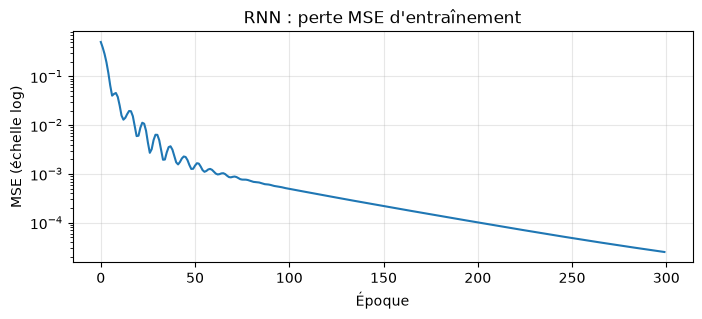

In [5]:
plt.figure(figsize=(8, 3))
plt.plot(historique)
plt.yscale("log")
plt.title("RNN : perte MSE d'entraînement")
plt.xlabel("Époque")
plt.ylabel("MSE (échelle log)")
plt.grid(True, alpha=0.3)
plt.show()

## 4. Tester sur `X_test`

In [6]:
modele.eval()
with torch.no_grad():
    predictions = modele(X_test)
    erreur_test = critere(predictions, y_test)
    mae_test = (predictions - y_test).abs().mean()

print(f"MSE test : {erreur_test.item():.6f}")
print(f"MAE test : {mae_test.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions[0].item():.4f}")

MSE test : 0.000028
MAE test : 0.004562
Valeur réelle  : -0.3639
Valeur prédite : -0.3601


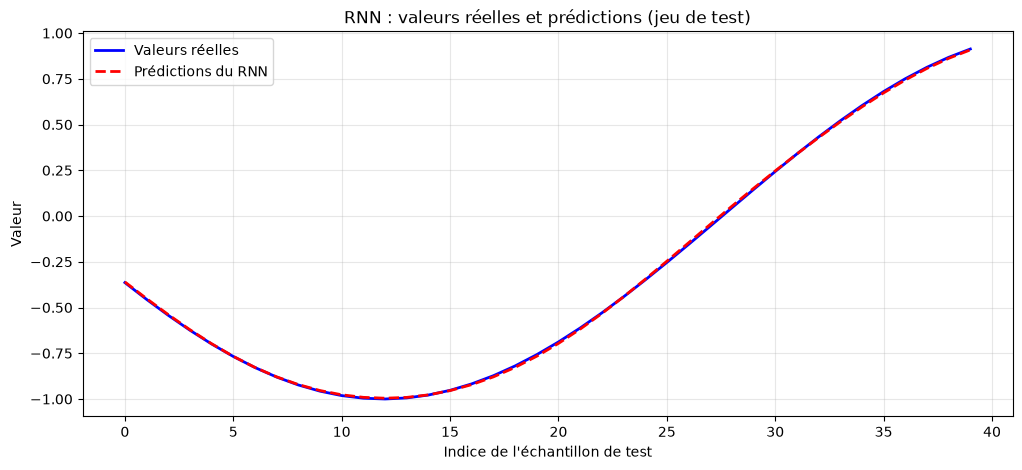

In [7]:
plt.figure(figsize=(12, 5))
plt.plot(y_test.reshape(-1), label="Valeurs réelles", color="blue", linewidth=2)
plt.plot(predictions.reshape(-1), label="Prédictions du RNN", color="red", linestyle="--", linewidth=2)
plt.title("RNN : valeurs réelles et prédictions (jeu de test)")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Conclusion

- Le RNN lit les 10 valeurs **une par une** et résume la séquence dans son dernier état caché $h_{10}$.
- Sur une sinusoïde, la dépendance est courte : un RNN simple suffit pour obtenir une très faible erreur de test.
- Limite : sur de longues séquences, les gradients peuvent **disparaître ou exploser** → motivation du LSTM.

➡️ Étape suivante : `03_lstm.ipynb`